In [5]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [6]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

In [12]:
import numpy as np
def print_unknown_array_dimensions(unknown_obj):
    # Safely convert to a numpy array framework
    arr = np.asanyarray(unknown_obj)
    
    print(f"Data Type: {type(unknown_obj)}")
    print(f"Number of dimensions (axes): {arr.ndim}")
    print(f"Exact shape (size per axis): {arr.shape}")

In [ ]:
import matplotlib.pyplot as plt

number_to_plot = 200
indices = 

Data Type: <class 'torch.Tensor'>
Number of dimensions (axes): 1
Exact shape (size per axis): (2048,)
62


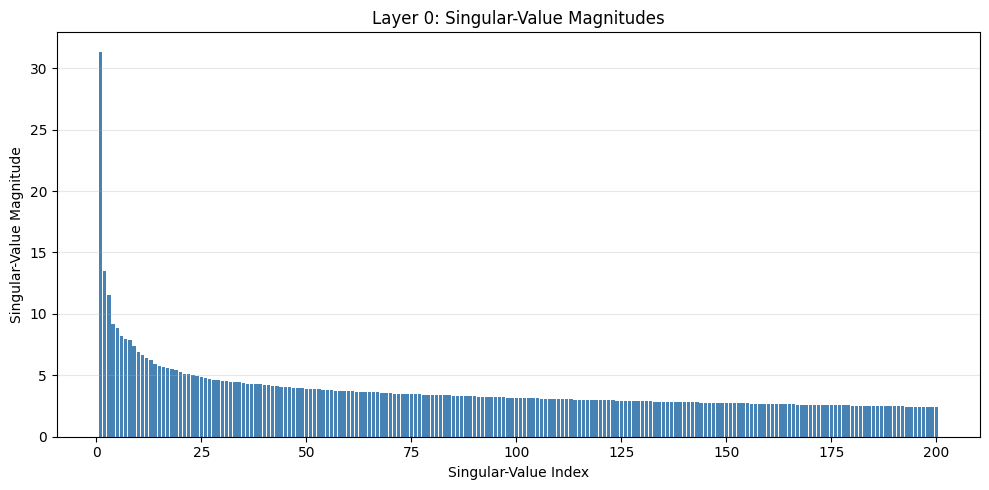

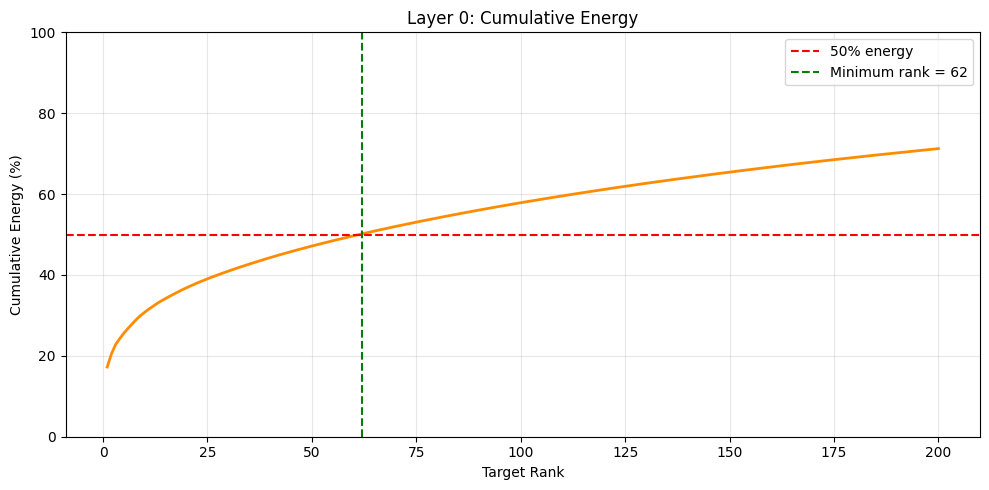

Data Type: <class 'torch.Tensor'>
Number of dimensions (axes): 1
Exact shape (size per axis): (2048,)
120


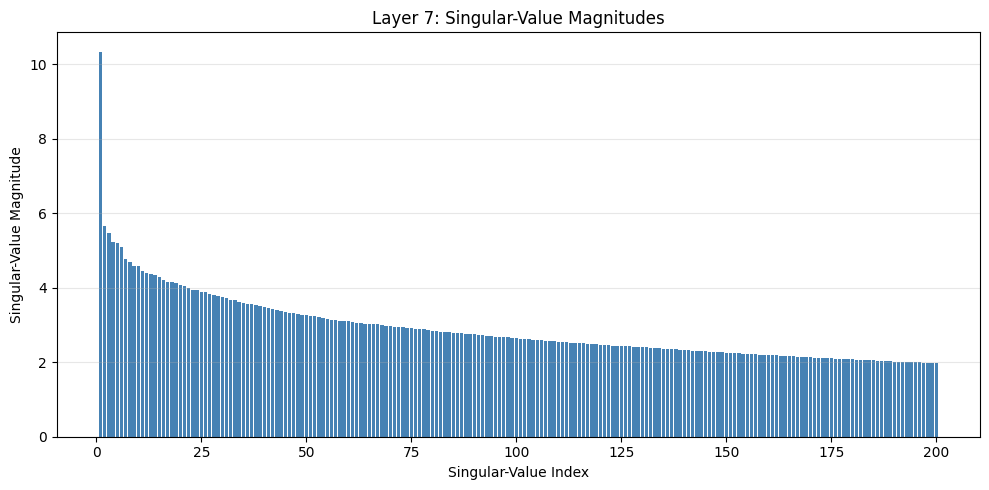

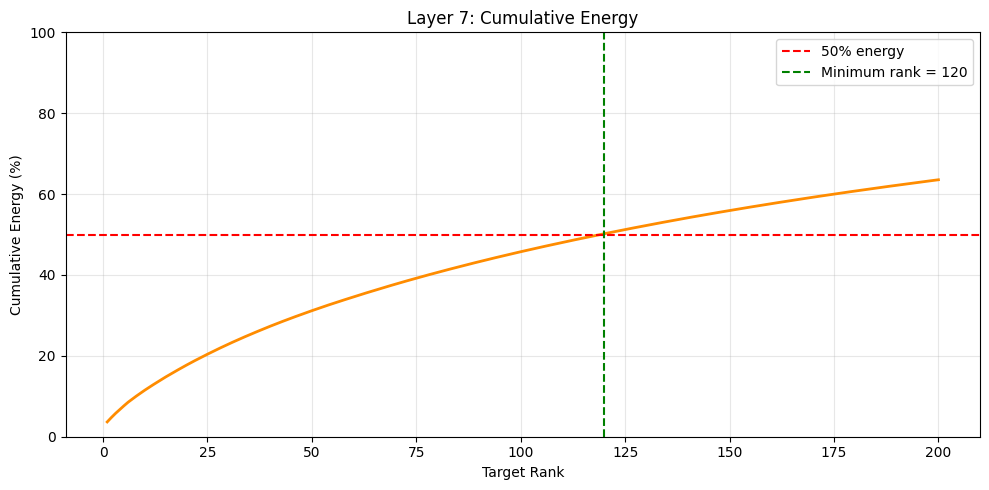

Data Type: <class 'torch.Tensor'>
Number of dimensions (axes): 1
Exact shape (size per axis): (2048,)
84


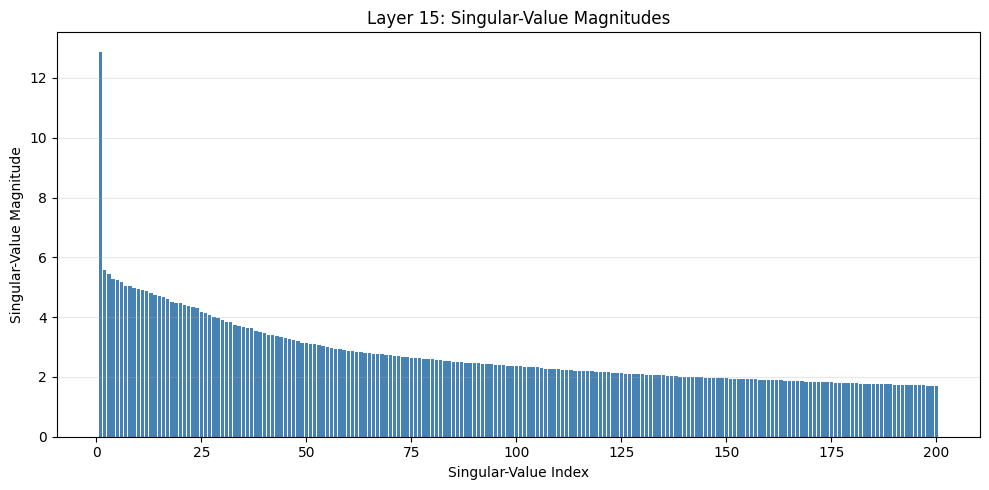

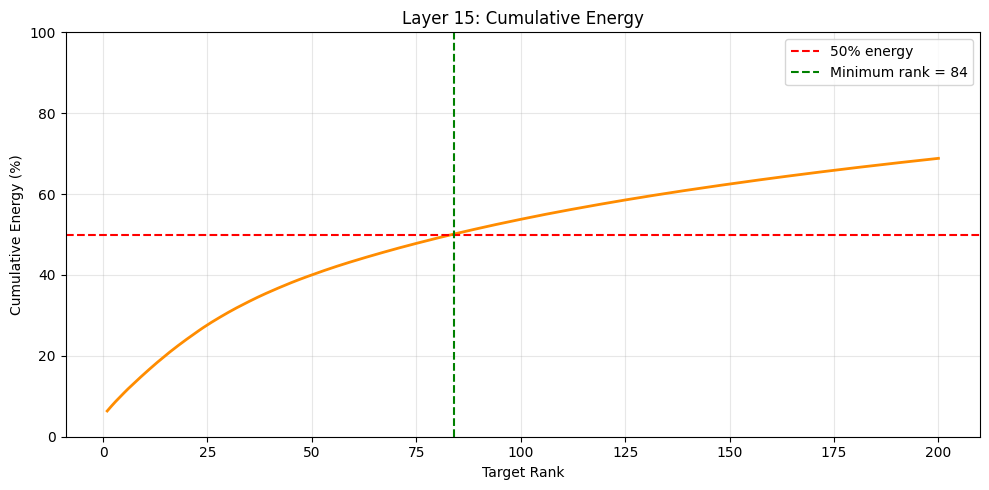

In [17]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""

layers = [0, 7, 15]

for layer in layers:
    q_weight = model.model.layers[layer].self_attn.q_proj.weight.detach()
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)
    print_unknown_array_dimensions(S)
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
    minimum_target_rank = torch.nonzero(energy_ratios >= 50, as_tuple=False)[0].item()+1
    print(minimum_target_rank)

    #Plot
    import matplotlib.pyplot as plt

    number_to_plot = 200
    indices = range(1, number_to_plot + 1)

    # Move values to CPU for Matplotlib
    singular_values = S[:number_to_plot].detach().cpu()
    cumulative_energy = energy_ratios[:number_to_plot].detach().cpu()

    # Singular value magnitude chart
    plt.figure(figsize=(10, 5))
    plt.bar(
        indices,
        singular_values,
        color="steelblue",
    )
    
    plt.title(f"Layer {layer}: Singular-Value Magnitudes")
    plt.xlabel("Singular-Value Index")
    plt.ylabel("Singular-Value Magnitude")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Cumulative energy chart :
    plt.figure(figsize=(10, 5))
    
    plt.plot(
        indices,
        cumulative_energy,
        color="darkorange",
        linewidth=2,
    )
    
    plt.axhline(
        y=50,
        color="red",
        linestyle="--",
        label="50% energy",
    )
    
    # Display the minimum target rank if it is within the first 200
    if minimum_target_rank <= number_to_plot:
        plt.axvline(
            x=minimum_target_rank,
            color="green",
            linestyle="--",
            label=f"Minimum rank = {minimum_target_rank}",
        )
    
    plt.title(f"Layer {layer}: Cumulative Energy")
    plt.xlabel("Target Rank")
    plt.ylabel("Cumulative Energy (%)")
    plt.ylim(0, 100)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    


